In [1]:
# ── Cell 0: imports, paths, style ───────────────────────────────────────────
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path("/home/brandon/energy_llm/results")
EXPERIMENTS  = ["e1", "e2", "e3"]
NAMES        = {"e1": "Qwen — TruthfulQA",
                "e2": "LLaMA — TruthfulQA",
                "e3": "Qwen — TriviaQA"}

PALETTE = {
    "factual" : "#3C6E8F",
    "halluc"  : "#B5544E",
    "ink"     : "#2B2B2B",
    "muted"   : "#6B6B6B",
    "grid"    : "#D6D9DC",
    "panel"   : "#F4F6F8",
}

plt.rcParams.update({
    "font.family"        : "serif",
    "font.size"          : 10,
    "axes.titlesize"     : 11,
    "axes.titleweight"   : "bold",
    "axes.labelsize"     : 10,
    "axes.edgecolor"     : PALETTE["muted"],
    "axes.linewidth"     : 0.8,
    "axes.spines.top"    : False,
    "axes.spines.right"  : False,
    "text.color"         : PALETTE["ink"],
    "axes.labelcolor"    : PALETTE["ink"],
    "xtick.color"        : PALETTE["muted"],
    "ytick.color"        : PALETTE["muted"],
    "figure.dpi"         : 150,
})

In [2]:
# ── Cell 1: load calibration JSONs ──────────────────────────────────────────
calib = {}
for exp in EXPERIMENTS:
    path = RESULTS_DIR / exp / "calibration" / "calibration.json"
    raw  = json.loads(path.read_text())
    calib[exp] = raw

# diagnostic: inspect structure of one file before assuming field names
print("Keys in e1 calibration.json:")
print(list(calib["e1"].keys()))
print()
print("beta_star values:")
for exp in EXPERIMENTS:
    print(f"  {exp}: {calib[exp].get('beta_star', 'NOT FOUND')}")

Keys in e1 calibration.json:
['beta_star', 'clamped', 'target_norm_entropy', 'beta_grid', 'mean_norm_entropy_curve', 'calibration_sample_ids', 'n_calibration_samples', 'model_id', 'bank_id']

beta_star values:
  e1: 1.9578453524806456
  e2: 5.058341935910842
  e3: 1.9881622367733318


In [4]:
# ── Cell 2: extract curve data ───────────────────────────────────────────────
# Run Cell 1 first and inspect the keys; adjust field names below if needed.
# Common structures handled: dict with 'beta_grid'+'h_bar_curve',
# or list of dicts under 'calibration_curve', or 'entropy_curve'.

def extract_curve(raw):
    """Return (betas, h_bars, beta_star) from a calibration.json dict."""
    beta_star = raw["beta_star"]
    betas     = np.array(raw["beta_grid"])
    h_bars    = np.array(raw["mean_norm_entropy_curve"])
    return betas, h_bars, beta_star

curves = {}
for exp in EXPERIMENTS:
    curves[exp] = extract_curve(calib[exp])
    betas, h_bars, bstar = curves[exp]
    print(f"{exp}: beta_star={bstar:.4f}  "
          f"beta_grid={betas.tolist()}  "
          f"h_bar range=[{h_bars.min():.3f}, {h_bars.max():.3f}]")

e1: beta_star=1.9578  beta_grid=[1, 2, 5, 10, 15, 20, 30, 50, 100]  h_bar range=[0.005, 0.871]
e2: beta_star=5.0583  beta_grid=[1, 2, 5, 10, 15, 20, 30, 50, 100]  h_bar range=[0.010, 0.991]
e3: beta_star=1.9882  beta_grid=[1, 2, 5, 10, 15, 20, 30, 50, 100]  h_bar range=[0.005, 0.880]


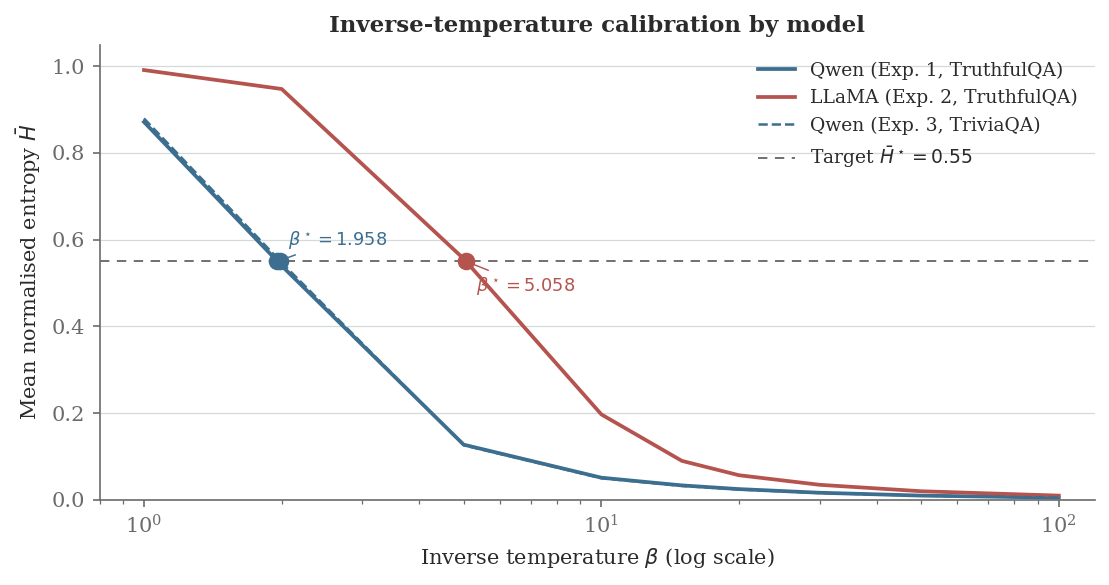

Saved calibration_curve.png to all figure directories.


In [5]:
# ── Cell 3: plot ─────────────────────────────────────────────────────────────
TARGET = 0.55

# visual spec per experiment
SPEC = {
    "e1": dict(color=PALETTE["factual"], ls="-",  lw=1.8,
               label="Qwen (Exp. 1, TruthfulQA)"),
    "e2": dict(color=PALETTE["halluc"],  ls="-",  lw=1.8,
               label="LLaMA (Exp. 2, TruthfulQA)"),
    "e3": dict(color=PALETTE["factual"], ls="--", lw=1.2,
               label="Qwen (Exp. 3, TriviaQA)"),
}

fig, ax = plt.subplots(figsize=(7.5, 4.0))

for exp in EXPERIMENTS:
    betas, h_bars, beta_star = curves[exp]
    sp = SPEC[exp]
    ax.plot(betas, h_bars, color=sp["color"], ls=sp["ls"],
            lw=sp["lw"], label=sp["label"], zorder=3)
    ax.scatter([beta_star], [TARGET], color=sp["color"],
               s=55, zorder=4, clip_on=False)
    # annotate beta_star only for e1 and e2 (e3 nearly identical to e1)
    if exp in ("e1", "e2"):
        offset = (5, 8) if exp == "e1" else (5, -14)
        ax.annotate(
            f"$\\beta^\\star = {beta_star:.3f}$",
            xy=(beta_star, TARGET),
            xytext=offset, textcoords="offset points",
            fontsize=8.5, color=sp["color"],
            arrowprops=dict(arrowstyle="-", color=sp["color"],
                            lw=0.7, shrinkA=0, shrinkB=3),
        )

# target line
ax.axhline(TARGET, color=PALETTE["ink"], lw=0.9,
           ls=(0, (5, 4)), alpha=0.7, zorder=2,
           label=f"Target $\\bar{{H}}^\\star = {TARGET}$")

ax.set_xscale("log")
ax.set_xlabel("Inverse temperature $\\beta$ (log scale)")
ax.set_ylabel("Mean normalised entropy $\\bar{H}$")
ax.set_title("Inverse-temperature calibration by model")
ax.set_ylim(0, 1.05)
ax.set_xlim(betas.min() * 0.8, betas.max() * 1.2)
ax.grid(axis="y", color=PALETTE["grid"], lw=0.6, zorder=0)
ax.legend(frameon=False, fontsize=9, loc="upper right")

fig.tight_layout()

# save to all figure directories
for exp in EXPERIMENTS:
    out = RESULTS_DIR / exp / "figures"
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / "calibration_curve.png", dpi=150, bbox_inches="tight")

plt.show()
print("Saved calibration_curve.png to all figure directories.")

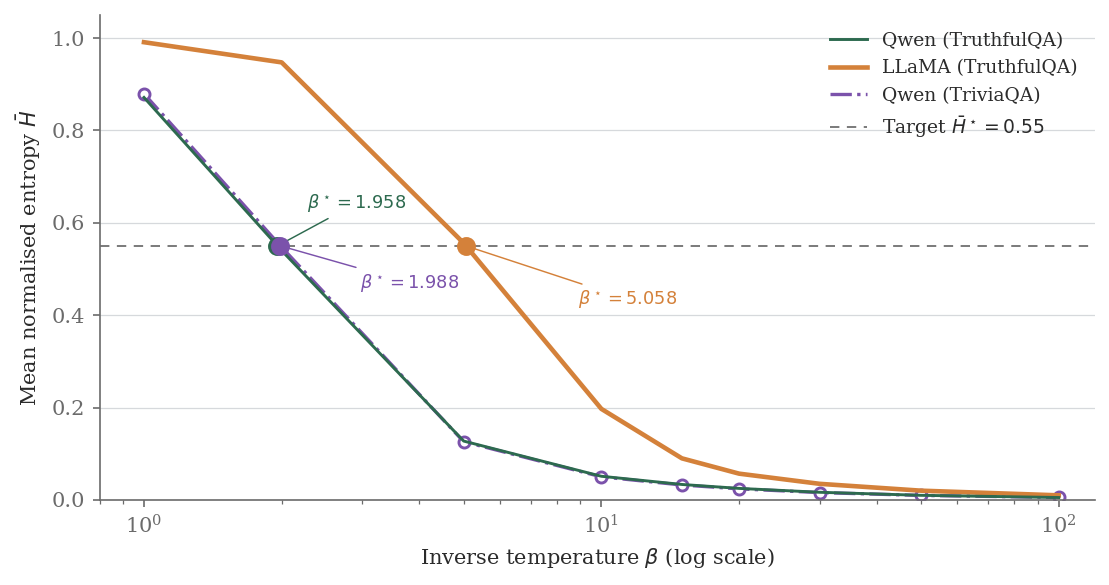

Saved.


In [11]:
# ── Cell 3 (versión final) ───────────────────────────────────────────────────
TARGET = 0.55

QWEN_DARK = "#2D6A4F"   # verde oscuro  → E1
E3_COLOR  = "#7B52AB"   # púrpura       → E3 (mismo modelo, contraste claro)
LLAMA_COL = "#D4813A"   # ámbar         → E2

SPEC = {
    "e1": dict(color=QWEN_DARK, ls="-",   lw=1.4, zorder=4, marker=None,
               label="Qwen (TruthfulQA)"),
    "e2": dict(color=LLAMA_COL, ls="-",   lw=2.2, zorder=3, marker=None,
               label="LLaMA (TruthfulQA)"),
    "e3": dict(color=E3_COLOR,  ls="-.",  lw=1.6, zorder=2, marker="o",
               label="Qwen (TriviaQA)"),
}

# todas las anotaciones a la derecha del punto beta_star
ANNOT = {
    "e1": dict(xytext=( 14,  18), ha="left"),   # arriba-derecha
    "e3": dict(xytext=( 38, -20), ha="left"),   # derecha-abajo, desplazada para no tapar E1
    "e2": dict(xytext=( 54, -28), ha="left"),   # abajo-derecha
}

fig, ax = plt.subplots(figsize=(7.5, 4.0))

for exp in EXPERIMENTS:
    betas, h_bars, beta_star = curves[exp]
    sp = SPEC[exp]

    ax.plot(betas, h_bars,
            color=sp["color"], ls=sp["ls"], lw=sp["lw"],
            zorder=sp["zorder"], label=sp["label"])

    if sp["marker"]:
        ax.scatter(betas, h_bars,
                   color=sp["color"], s=28, zorder=sp["zorder"],
                   marker="o", facecolors="white", linewidths=1.4)

    ax.scatter([beta_star], [TARGET],
               color=sp["color"], s=65, zorder=6, clip_on=False)

    if exp in ANNOT:
        a = ANNOT[exp]
        ax.annotate(
            f"$\\beta^\\star = {beta_star:.3f}$",
            xy=(beta_star, TARGET),
            xytext=a["xytext"],
            textcoords="offset points",
            fontsize=8.5, color=sp["color"], ha=a["ha"],
            arrowprops=dict(arrowstyle="-", color=sp["color"],
                            lw=0.7, shrinkA=0, shrinkB=4),
        )

ax.axhline(TARGET, color=PALETTE["ink"], lw=0.9,
           ls=(0, (5, 4)), alpha=0.65, zorder=1,
           label=f"Target $\\bar{{H}}^\\star = {TARGET}$")

ax.set_xscale("log")
ax.set_xlabel("Inverse temperature $\\beta$ (log scale)")
ax.set_ylabel("Mean normalised entropy $\\bar{H}$")
ax.set_ylim(0, 1.05)
ax.set_xlim(betas.min() * 0.8, betas.max() * 1.2)
ax.grid(axis="y", color=PALETTE["grid"], lw=0.6, zorder=0)
ax.legend(frameon=False, fontsize=9, loc="upper right")

fig.tight_layout()

for exp in EXPERIMENTS:
    out = RESULTS_DIR / exp / "figures"
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / "calibration_curve.png", dpi=150, bbox_inches="tight")

plt.show()
print("Saved.")